# 05 — Post-Election Evaluation of the 2026 Riksdag Turnout Forecast

## Objective

This notebook evaluates the municipality-level voter-turnout predictions
that were frozen before the 2026 Swedish Riksdag election.

The frozen predictions are compared with the official final 2026
municipality-level turnout results published by Valmyndigheten.

The original forecasts are not retrained or modified after observing
the election outcome.

In [24]:
import pandas as pd
import json
import zipfile
from pathlib import Path

In [25]:
results_zip = Path("../data/raw/Val_2026_slutlig_00_RD.zip")

print("File exists:", results_zip.exists())
print("Path:", results_zip)

File exists: True
Path: ..\data\raw\Val_2026_slutlig_00_RD.zip


In [26]:
with zipfile.ZipFile(results_zip, "r") as z:
    file_names = z.namelist()

file_names

['Val_2026_slutlig_rostfordelning_00_RD.json',
 'Val_2026_slutlig_mandatfordelning_00_RD.json',
 'Val_2026_slutlig_rostfordelning_00_RD_sign.sha256',
 'Val_2026_slutlig_mandatfordelning_00_RD_sign.sha256',
 'Val_2026_slutlig_summering_RD.json',
 'Val_2026_slutlig_summering_RD_sign.sha256']

In [27]:
summary_files = [
    name for name in file_names
    if "summering" in name and name.endswith(".json")
]

print(summary_files)

['Val_2026_slutlig_summering_RD.json']


In [28]:
summary_file = summary_files[0]

with zipfile.ZipFile(results_zip, "r") as z:
    with z.open(summary_file) as f:
        election_data = json.load(f)

type(election_data)

dict

In [29]:
election_data.keys()


dict_keys(['valtillfalle', 'valklass', 'rakningstillfalle', 'valtyp', 'valdatum', 'tidigareValdatum', 'senasteUppdateringstid', 'antalUppdateringar', 'antalValdistriktRaknade', 'antalValdistriktSomSkaRaknas', 'kommuner'])

In [30]:
print("Election type:", election_data["valtyp"])
print("Election date:", election_data["valdatum"])
print("Counting stage:", election_data["rakningstillfalle"])

print(
    "Electoral districts counted:",
    election_data["antalValdistriktRaknade"],
    "/",
    election_data["antalValdistriktSomSkaRaknas"]
)

print("Number of municipalities:", len(election_data["kommuner"]))

Election type: RD
Election date: 2026-09-13
Counting stage: slutlig
Electoral districts counted: 6626 / 6626
Number of municipalities: 290


In [31]:
first_municipality = election_data["kommuner"][0]

first_municipality

{'senasteUppdateringstid': '2026-09-19T14:53:14',
 'senasteRapporteringstid': '2026-09-18T20:22:36',
 'totaltAntalRoster': 28268,
 'antalRostberattigade': 35090,
 'valdeltagande': 80.56,
 'antalRostberattigadeIRaknadeValdistrikt': 35090,
 'antalValdistriktRaknade': 29,
 'antalValdistriktSomSkaRaknas': 29,
 'totaltAntalRosterForegaendeVal': 26207,
 'antalRostberattigadeForegaendeVal': 32973,
 'valdeltagandeForegaendeVal': 79.48,
 'forandringTotaltAntalRoster': 2061,
 'forandringValdeltagande': 1.08,
 'forandringAntalRostberattigade': 2117,
 'namn': 'Upplands Väsby kommun',
 'kommunkod': '0114',
 'lankod': '01',
 'statusJamforelse': 'Kan jämföras',
 'rostfordelning': {'rosterPaverkaMandat': {'antalRoster': 28028,
   'antalRosterForegaendeVal': 25908,
   'forandringAntalRoster': 2120,
   'partiRoster': [{'partibeteckning': 'Moderaterna',
     'partiforkortning': 'M',
     'partikod': '0001',
     'fargkod': '#66BEE6',
     'ordningsnummer': 1,
     'antalRoster': 5842,
     'andelRoster':

In [32]:
{
    "municipality_code": first_municipality["kommunkod"],
    "municipality_name": first_municipality["namn"],
    "turnout_2026_pct": first_municipality["valdeltagande"],
    "eligible_voters": first_municipality["antalRostberattigade"],
    "previous_turnout_pct": first_municipality["valdeltagandeForegaendeVal"]
}

{'municipality_code': '0114',
 'municipality_name': 'Upplands Väsby kommun',
 'turnout_2026_pct': 80.56,
 'eligible_voters': 35090,
 'previous_turnout_pct': 79.48}

In [33]:
municipality_rows = []

for municipality in election_data["kommuner"]:
    municipality_rows.append({
        "municipality_code": municipality["kommunkod"],
        "municipality_name": municipality["namn"],
        "turnout_2026_pct": municipality["valdeltagande"],
        "eligible_voters": municipality["antalRostberattigade"],
        "total_votes": municipality["totaltAntalRoster"],
        "previous_turnout_pct": municipality["valdeltagandeForegaendeVal"]
    })

actual_2026 = pd.DataFrame(municipality_rows)

actual_2026.head()

,municipality_code,municipality_name,turnout_2026_pct,eligible_voters,total_votes,previous_turnout_pct
0,0114,Upplands Väsby kommun,80.56,35090,28268,79.48
1,0115,Vallentuna kommun,87.84,26044,22877,87.44
2,0117,Österåkers kommun,87.85,36603,32156,87.30
3,0120,Värmdö kommun,89.06,35029,31197,88.39
4,0123,Järfälla kommun,81.00,63488,51424,79.38


In [34]:
print("Shape:", actual_2026.shape)

print(
    "Unique municipality codes:",
    actual_2026["municipality_code"].nunique()
)

print(
    "Duplicate municipality codes:",
    actual_2026["municipality_code"].duplicated().sum()
)

print("\nMissing values:")
print(actual_2026.isna().sum())

Shape: (290, 6)
Unique municipality codes: 290
Duplicate municipality codes: 0

Missing values:
municipality_code       0
municipality_name       0
turnout_2026_pct        0
eligible_voters         0
total_votes             0
previous_turnout_pct    0
dtype: int64


In [35]:
actual_2026_path = Path(
    "../data/processed/actual_turnout_2026_municipalities.csv"
)

actual_2026.to_csv(actual_2026_path, index=False)

print("Saved to:", actual_2026_path)

Saved to: ..\data\processed\actual_turnout_2026_municipalities.csv


In [36]:
frozen_predictions_path = Path(
    "../results/turnout_predictions_2026_frozen_2026-09-09.csv"
)

predictions_2026 = pd.read_csv(
    frozen_predictions_path,
    dtype={"municipality_code": str}
)

predictions_2026.head()

,municipality_code,municipality_name,election_year,forecast_generated_on,previous_turnout_pct,baseline_prediction,linear_regression_prediction,decision_tree_prediction,random_forest_prediction
0,0114,Upplands Väsby,2026,2026-09-09,79.5,79.5,81.203981,80.372727,80.300126
1,0115,Vallentuna,2026,2026-09-09,87.4,87.4,87.237989,89.947619,89.168827
2,0117,Österåker,2026,2026-09-09,87.3,87.3,87.045843,89.947619,89.207286
3,0120,Värmdö,2026,2026-09-09,88.4,88.4,87.963506,89.947619,89.601141
4,0123,Järfälla,2026,2026-09-09,79.4,79.4,80.917239,80.372727,79.788386


In [37]:
predictions_2026.shape

(290, 9)

In [38]:
print("Shape:", predictions_2026.shape)

print(
    "Unique municipality codes:",
    predictions_2026["municipality_code"].nunique()
)

print(
    "Duplicate municipality codes:",
    predictions_2026["municipality_code"].duplicated().sum()
)

print(
    "Election years:",
    predictions_2026["election_year"].unique()
)

print(
    "Forecast dates:",
    predictions_2026["forecast_generated_on"].unique()
)

print("\nMissing values:")
print(predictions_2026.isna().sum())

Shape: (290, 9)
Unique municipality codes: 290
Duplicate municipality codes: 0
Election years: [2026]
Forecast dates: <StringArray>
['2026-09-09']
Length: 1, dtype: str

Missing values:
municipality_code               0
municipality_name               0
election_year                   0
forecast_generated_on           0
previous_turnout_pct            0
baseline_prediction             0
linear_regression_prediction    0
decision_tree_prediction        0
random_forest_prediction        0
dtype: int64


In [39]:
baseline_matches_previous = (
    predictions_2026["baseline_prediction"]
    == predictions_2026["previous_turnout_pct"]
)

print(
    "Rows where baseline equals previous turnout:",
    baseline_matches_previous.sum()
)

print(
    "Rows where they differ:",
    (~baseline_matches_previous).sum()
)

Rows where baseline equals previous turnout: 290
Rows where they differ: 0


In [40]:
evaluation_2026 = predictions_2026.merge(
    actual_2026[
        [
            "municipality_code",
            "turnout_2026_pct",
            "eligible_voters",
            "total_votes"
        ]
    ],
    on="municipality_code",
    how="inner",
    validate="one_to_one"
)

evaluation_2026.head()

,municipality_code,municipality_name,election_year,forecast_generated_on,previous_turnout_pct,baseline_prediction,linear_regression_prediction,decision_tree_prediction,random_forest_prediction,turnout_2026_pct,eligible_voters,total_votes
0,0114,Upplands Väsby,2026,2026-09-09,79.5,79.5,81.203981,80.372727,80.300126,80.56,35090,28268
1,0115,Vallentuna,2026,2026-09-09,87.4,87.4,87.237989,89.947619,89.168827,87.84,26044,22877
2,0117,Österåker,2026,2026-09-09,87.3,87.3,87.045843,89.947619,89.207286,87.85,36603,32156
3,0120,Värmdö,2026,2026-09-09,88.4,88.4,87.963506,89.947619,89.601141,89.06,35029,31197
4,0123,Järfälla,2026,2026-09-09,79.4,79.4,80.917239,80.372727,79.788386,81.00,63488,51424


In [41]:
evaluation_2026.shape

(290, 12)

In [42]:
print("Rows:", len(evaluation_2026))

print(
    "Unique municipality codes:",
    evaluation_2026["municipality_code"].nunique()
)

print(
    "Missing actual turnout:",
    evaluation_2026["turnout_2026_pct"].isna().sum()
)

print(
    "Missing baseline predictions:",
    evaluation_2026["baseline_prediction"].isna().sum()
)

print(
    "Missing linear regression predictions:",
    evaluation_2026["linear_regression_prediction"].isna().sum()
)

print(
    "Missing decision tree predictions:",
    evaluation_2026["decision_tree_prediction"].isna().sum()
)

print(
    "Missing random forest predictions:",
    evaluation_2026["random_forest_prediction"].isna().sum()
)

Rows: 290
Unique municipality codes: 290
Missing actual turnout: 0
Missing baseline predictions: 0
Missing linear regression predictions: 0
Missing decision tree predictions: 0
Missing random forest predictions: 0


In [43]:
evaluation_2026["baseline_error"] = (
    evaluation_2026["baseline_prediction"]
    - evaluation_2026["turnout_2026_pct"]
)

evaluation_2026["linear_regression_error"] = (
    evaluation_2026["linear_regression_prediction"]
    - evaluation_2026["turnout_2026_pct"]
)

evaluation_2026["decision_tree_error"] = (
    evaluation_2026["decision_tree_prediction"]
    - evaluation_2026["turnout_2026_pct"]
)

evaluation_2026["random_forest_error"] = (
    evaluation_2026["random_forest_prediction"]
    - evaluation_2026["turnout_2026_pct"]
)

evaluation_2026[
    [
        "municipality_name",
        "turnout_2026_pct",
        "baseline_prediction",
        "baseline_error",
        "linear_regression_prediction",
        "linear_regression_error",
        "decision_tree_prediction",
        "decision_tree_error",
        "random_forest_prediction",
        "random_forest_error"
    ]
].head()

,municipality_name,turnout_2026_pct,baseline_prediction,baseline_error,linear_regression_prediction,linear_regression_error,decision_tree_prediction,decision_tree_error,random_forest_prediction,random_forest_error
0,Upplands Väsby,80.56,79.5,-1.06,81.203981,0.643981,80.372727,-0.187273,80.300126,-0.259874
1,Vallentuna,87.84,87.4,-0.44,87.237989,-0.602011,89.947619,2.107619,89.168827,1.328827
2,Österåker,87.85,87.3,-0.55,87.045843,-0.804157,89.947619,2.097619,89.207286,1.357286
3,Värmdö,89.06,88.4,-0.66,87.963506,-1.096494,89.947619,0.887619,89.601141,0.541141
4,Järfälla,81.00,79.4,-1.60,80.917239,-0.082761,80.372727,-0.627273,79.788386,-1.211614


In [44]:
evaluation_2026[
    [
        "municipality_code",
        "municipality_name",
        "turnout_2026_pct",
        "baseline_prediction",
        "linear_regression_prediction",
        "decision_tree_prediction",
        "random_forest_prediction",
        "baseline_error",
        "linear_regression_error",
        "decision_tree_error",
        "random_forest_error"
    ]
].head()

,municipality_code,municipality_name,turnout_2026_pct,baseline_prediction,linear_regression_prediction,decision_tree_prediction,random_forest_prediction,baseline_error,linear_regression_error,decision_tree_error,random_forest_error
0,0114,Upplands Väsby,80.56,79.5,81.203981,80.372727,80.300126,-1.06,0.643981,-0.187273,-0.259874
1,0115,Vallentuna,87.84,87.4,87.237989,89.947619,89.168827,-0.44,-0.602011,2.107619,1.328827
2,0117,Österåker,87.85,87.3,87.045843,89.947619,89.207286,-0.55,-0.804157,2.097619,1.357286
3,0120,Värmdö,89.06,88.4,87.963506,89.947619,89.601141,-0.66,-1.096494,0.887619,0.541141
4,0123,Järfälla,81.00,79.4,80.917239,80.372727,79.788386,-1.60,-0.082761,-0.627273,-1.211614


In [45]:
evaluation_2026["baseline_absolute_error"] = (
    evaluation_2026["baseline_error"].abs()
)

evaluation_2026["linear_regression_absolute_error"] = (
    evaluation_2026["linear_regression_error"].abs()
)

evaluation_2026["decision_tree_absolute_error"] = (
    evaluation_2026["decision_tree_error"].abs()
)

evaluation_2026["random_forest_absolute_error"] = (
    evaluation_2026["random_forest_error"].abs()
)

evaluation_2026[
    [
        "municipality_name",
        "baseline_absolute_error",
        "linear_regression_absolute_error",
        "decision_tree_absolute_error",
        "random_forest_absolute_error"
    ]
].head()

,municipality_name,baseline_absolute_error,linear_regression_absolute_error,decision_tree_absolute_error,random_forest_absolute_error
0,Upplands Väsby,1.06,0.643981,0.187273,0.259874
1,Vallentuna,0.44,0.602011,2.107619,1.328827
2,Österåker,0.55,0.804157,2.097619,1.357286
3,Värmdö,0.66,1.096494,0.887619,0.541141
4,Järfälla,1.60,0.082761,0.627273,1.211614


In [46]:
baseline_mae = evaluation_2026["baseline_absolute_error"].mean()

linear_regression_mae = (
    evaluation_2026["linear_regression_absolute_error"].mean()
)

decision_tree_mae = (
    evaluation_2026["decision_tree_absolute_error"].mean()
)

random_forest_mae = (
    evaluation_2026["random_forest_absolute_error"].mean()
)

print("Baseline MAE:", baseline_mae)
print("Linear Regression MAE:", linear_regression_mae)
print("Decision Tree MAE:", decision_tree_mae)
print("Random Forest MAE:", random_forest_mae)

Baseline MAE: 0.713827586206897
Linear Regression MAE: 1.5117624816865456
Decision Tree MAE: 1.5348080055202578
Random Forest MAE: 1.5495793348192812


In [47]:
baseline_rmse = (
    (evaluation_2026["baseline_error"] ** 2).mean()
) ** 0.5

linear_regression_rmse = (
    (evaluation_2026["linear_regression_error"] ** 2).mean()
) ** 0.5

decision_tree_rmse = (
    (evaluation_2026["decision_tree_error"] ** 2).mean()
) ** 0.5

random_forest_rmse = (
    (evaluation_2026["random_forest_error"] ** 2).mean()
) ** 0.5

print("Baseline RMSE:", baseline_rmse)
print("Linear Regression RMSE:", linear_regression_rmse)
print("Decision Tree RMSE:", decision_tree_rmse)
print("Random Forest RMSE:", random_forest_rmse)


Baseline RMSE: 0.9659526296659797
Linear Regression RMSE: 1.857996168846096
Decision Tree RMSE: 1.837523960454798
Random Forest RMSE: 1.7768513446728733


In [48]:
actual_mean = evaluation_2026["turnout_2026_pct"].mean()

total_variation = (
    (evaluation_2026["turnout_2026_pct"] - actual_mean) ** 2
).sum()

baseline_residual = (
    evaluation_2026["baseline_error"] ** 2
).sum()

linear_regression_residual = (
    evaluation_2026["linear_regression_error"] ** 2
).sum()

decision_tree_residual = (
    evaluation_2026["decision_tree_error"] ** 2
).sum()

random_forest_residual = (
    evaluation_2026["random_forest_error"] ** 2
).sum()

baseline_r2 = 1 - (baseline_residual / total_variation)

linear_regression_r2 = 1 - (
    linear_regression_residual / total_variation
)

decision_tree_r2 = 1 - (
    decision_tree_residual / total_variation
)

random_forest_r2 = 1 - (
    random_forest_residual / total_variation
)

print("Baseline R²:", baseline_r2)
print("Linear Regression R²:", linear_regression_r2)
print("Decision Tree R²:", decision_tree_r2)
print("Random Forest R²:", random_forest_r2)

Baseline R²: 0.8923975297634373
Linear Regression R²: 0.6018926354637243
Decision Tree R²: 0.6106173424263868
Random Forest R²: 0.6359066273073737


In [49]:
baseline_bias = evaluation_2026["baseline_error"].mean()

linear_regression_bias = (
    evaluation_2026["linear_regression_error"].mean()
)

decision_tree_bias = (
    evaluation_2026["decision_tree_error"].mean()
)

random_forest_bias = (
    evaluation_2026["random_forest_error"].mean()
)

print("Baseline bias:", baseline_bias)
print("Linear Regression bias:", linear_regression_bias)
print("Decision Tree bias:", decision_tree_bias)
print("Random Forest bias:", random_forest_bias)

Baseline bias: 0.1443793103448275
Linear Regression bias: 1.2306797851059683
Decision Tree bias: 1.3364781880509085
Random Forest bias: 1.3562534662166952


In [50]:
metrics_2026 = pd.DataFrame({
    "model": [
        "Baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_regression_mae,
        decision_tree_mae,
        random_forest_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_regression_rmse,
        decision_tree_rmse,
        random_forest_rmse
    ],
    "R2": [
        baseline_r2,
        linear_regression_r2,
        decision_tree_r2,
        random_forest_r2
    ],
    "Bias": [
        baseline_bias,
        linear_regression_bias,
        decision_tree_bias,
        random_forest_bias
    ]
})

metrics_2026.round(3)

,model,MAE,RMSE,R2,Bias
0,Baseline,0.714,0.966,0.892,0.144
1,Linear Regression,1.512,1.858,0.602,1.231
2,Decision Tree,1.535,1.838,0.611,1.336
3,Random Forest,1.550,1.777,0.636,1.356


In [51]:
evaluation_output_path = Path(
    "../results/post_election_evaluation_2026.csv"
)

metrics_output_path = Path(
    "../results/post_election_metrics_2026.csv"
)

evaluation_2026.to_csv(
    evaluation_output_path,
    index=False
)

metrics_2026.to_csv(
    metrics_output_path,
    index=False
)

print("Saved municipality evaluation to:")
print(evaluation_output_path)

print("\nSaved summary metrics to:")
print(metrics_output_path)

Saved municipality evaluation to:
..\results\post_election_evaluation_2026.csv

Saved summary metrics to:
..\results\post_election_metrics_2026.csv


In [52]:
historical_results_path = Path(
    "../results/historical_model_validation.csv"
)

historical_results = pd.read_csv(historical_results_path)

print("Shape:", historical_results.shape)
print("\nColumns:")
print(historical_results.columns.tolist())

historical_results.head(10)

Shape: (8, 5)

Columns:
['election', 'model', 'MAE', 'RMSE', 'R2']


,election,model,MAE,RMSE,R2
0,2018,Historical Baseline,1.338966,1.472565,0.663837
1,2018,Linear Regression,0.593239,0.785416,0.904369
2,2018,Decision Tree,0.710228,0.998625,0.845402
3,2018,Random Forest,0.583009,0.858991,0.885613
4,2022,Historical Baseline,2.340000,2.588689,0.298914
5,2022,Linear Regression,3.563705,3.717653,-0.445937
6,2022,Decision Tree,3.554260,3.763716,-0.481991
7,2022,Random Forest,3.490748,3.690441,-0.424847


In [53]:
# Make a copy so we do not modify the original historical results
historical_comparison = historical_results.copy()

# Use the same baseline name for every election
historical_comparison["model"] = historical_comparison["model"].replace(
    "Historical Baseline",
    "Baseline"
)

# Prepare the 2026 results in the same format
results_2026_for_comparison = metrics_2026[
    ["model", "MAE", "RMSE", "R2"]
].copy()

results_2026_for_comparison.insert(
    0,
    "election",
    2026
)

# Combine historical and prospective results
all_election_results = pd.concat(
    [
        historical_comparison,
        results_2026_for_comparison
    ],
    ignore_index=True
)

all_election_results

,election,model,MAE,RMSE,R2
0,2018,Baseline,1.338966,1.472565,0.663837
1,2018,Linear Regression,0.593239,0.785416,0.904369
2,2018,Decision Tree,0.710228,0.998625,0.845402
3,2018,Random Forest,0.583009,0.858991,0.885613
4,2022,Baseline,2.340000,2.588689,0.298914
5,2022,Linear Regression,3.563705,3.717653,-0.445937
6,2022,Decision Tree,3.554260,3.763716,-0.481991
7,2022,Random Forest,3.490748,3.690441,-0.424847
8,2026,Baseline,0.713828,0.965953,0.892398
9,2026,Linear Regression,1.511762,1.857996,0.601893


In [54]:
best_by_mae = all_election_results.loc[
    all_election_results.groupby("election")["MAE"].idxmin()
]

best_by_mae[
    ["election", "model", "MAE"]
]

,election,model,MAE
3,2018,Random Forest,0.583009
4,2022,Baseline,2.340000
8,2026,Baseline,0.713828


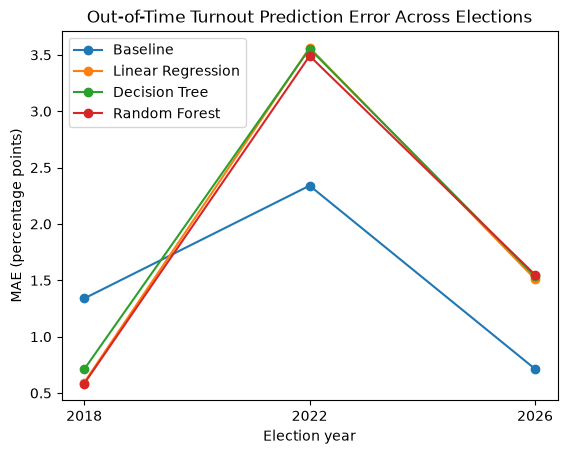

In [55]:
import matplotlib.pyplot as plt

for model_name in all_election_results["model"].unique():

    model_data = all_election_results[
        all_election_results["model"] == model_name
    ]

    plt.plot(
        model_data["election"],
        model_data["MAE"],
        marker="o",
        label=model_name
    )

plt.xlabel("Election year")
plt.ylabel("MAE (percentage points)")
plt.title("Out-of-Time Turnout Prediction Error Across Elections")

plt.xticks([2018, 2022, 2026])

plt.legend()

plt.show()

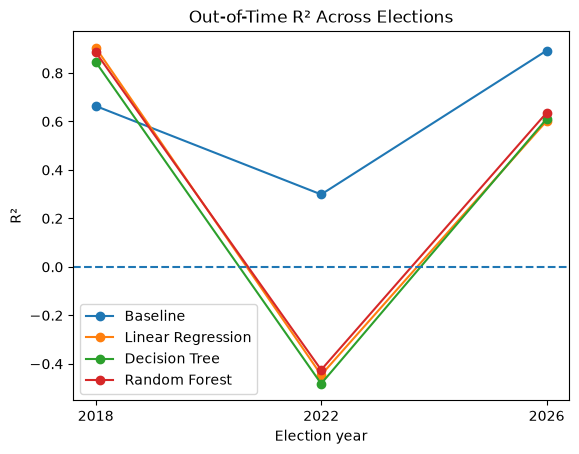

In [56]:
for model_name in all_election_results["model"].unique():

    model_data = all_election_results[
        all_election_results["model"] == model_name
    ]

    plt.plot(
        model_data["election"],
        model_data["R2"],
        marker="o",
        label=model_name
    )

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Election year")
plt.ylabel("R²")
plt.title("Out-of-Time R² Across Elections")

plt.xticks([2018, 2022, 2026])

plt.legend()

plt.show()

In [57]:
mean_municipal_turnout = (
    evaluation_2026["turnout_2026_pct"].mean()
)

weighted_turnout = (
    evaluation_2026["total_votes"].sum()
    / evaluation_2026["eligible_voters"].sum()
) * 100

print(
    "Mean municipality turnout:",
    mean_municipal_turnout
)

print(
    "Voter-weighted turnout:",
    weighted_turnout
)

Mean municipality turnout: 84.69562068965517
Voter-weighted turnout: 84.88525223394075


In [58]:
total_eligible_voters = evaluation_2026["eligible_voters"].sum()

baseline_weighted = (
    (
        evaluation_2026["baseline_prediction"]
        * evaluation_2026["eligible_voters"]
    ).sum()
    / total_eligible_voters
)

linear_regression_weighted = (
    (
        evaluation_2026["linear_regression_prediction"]
        * evaluation_2026["eligible_voters"]
    ).sum()
    / total_eligible_voters
)

decision_tree_weighted = (
    (
        evaluation_2026["decision_tree_prediction"]
        * evaluation_2026["eligible_voters"]
    ).sum()
    / total_eligible_voters
)

random_forest_weighted = (
    (
        evaluation_2026["random_forest_prediction"]
        * evaluation_2026["eligible_voters"]
    ).sum()
    / total_eligible_voters
)

print("Actual weighted turnout:", weighted_turnout)
print("Baseline weighted prediction:", baseline_weighted)
print("Linear Regression weighted prediction:", linear_regression_weighted)
print("Decision Tree weighted prediction:", decision_tree_weighted)
print("Random Forest weighted prediction:", random_forest_weighted)

Actual weighted turnout: 84.88525223394075
Baseline weighted prediction: 84.18793309945966
Linear Regression weighted prediction: 85.07778173629585
Decision Tree weighted prediction: 85.34892384779776
Random Forest weighted prediction: 85.26444354848441


In [59]:
weighted_comparison = pd.DataFrame({
    "model": [
        "Baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "weighted_prediction_pct": [
        baseline_weighted,
        linear_regression_weighted,
        decision_tree_weighted,
        random_forest_weighted
    ]
})

weighted_comparison["actual_weighted_turnout_pct"] = weighted_turnout

weighted_comparison["aggregate_error"] = (
    weighted_comparison["weighted_prediction_pct"]
    - weighted_comparison["actual_weighted_turnout_pct"]
)

weighted_comparison["absolute_aggregate_error"] = (
    weighted_comparison["aggregate_error"].abs()
)

weighted_comparison.round(3)

,model,weighted_prediction_pct,actual_weighted_turnout_pct,aggregate_error,absolute_aggregate_error
0,Baseline,84.188,84.885,-0.697,0.697
1,Linear Regression,85.078,84.885,0.193,0.193
2,Decision Tree,85.349,84.885,0.464,0.464
3,Random Forest,85.264,84.885,0.379,0.379


In [60]:
weighted_output_path = Path(
    "../results/weighted_aggregate_comparison_2026.csv"
)

weighted_comparison.to_csv(
    weighted_output_path,
    index=False
)

print("Saved weighted aggregate comparison to:")
print(weighted_output_path)

Saved weighted aggregate comparison to:
..\results\weighted_aggregate_comparison_2026.csv


In [61]:
baseline_worst = evaluation_2026.nlargest(
    10,
    "baseline_absolute_error"
)[
    [
        "municipality_code",
        "municipality_name",
        "turnout_2026_pct",
        "baseline_prediction",
        "baseline_error",
        "baseline_absolute_error"
    ]
]

baseline_worst

,municipality_code,municipality_name,turnout_2026_pct,baseline_prediction,baseline_error,baseline_absolute_error
7,0127,Botkyrka,76.01,71.3,-4.71,4.71
17,0181,Södertälje,74.63,70.6,-4.03,4.03
116,1280,Malmö,80.12,77.2,-2.92,2.92
49,0563,Valdemarsvik,84.33,87.1,2.77,2.77
253,2303,Ragunda,82.18,84.8,2.62,2.62
246,2260,Ånge,81.95,84.5,2.55,2.55
205,1880,Örebro,86.60,84.1,-2.50,2.50
254,2305,Bräcke,80.44,82.7,2.26,2.26
268,2422,Sorsele,83.55,81.3,-2.25,2.25
97,1231,Burlöv,76.71,74.5,-2.21,2.21


In [62]:
worst_municipalities = pd.DataFrame({
    "Baseline": (
        evaluation_2026
        .nlargest(10, "baseline_absolute_error")
        ["municipality_name"]
        .reset_index(drop=True)
    ),

    "Linear Regression": (
        evaluation_2026
        .nlargest(10, "linear_regression_absolute_error")
        ["municipality_name"]
        .reset_index(drop=True)
    ),

    "Decision Tree": (
        evaluation_2026
        .nlargest(10, "decision_tree_absolute_error")
        ["municipality_name"]
        .reset_index(drop=True)
    ),

    "Random Forest": (
        evaluation_2026
        .nlargest(10, "random_forest_absolute_error")
        ["municipality_name"]
        .reset_index(drop=True)
    )
})

worst_municipalities

,Baseline,Linear Regression,Decision Tree,Random Forest
0,Botkyrka,Haparanda,Haparanda,Haparanda
1,Södertälje,Övertorneå,Malmö,Malmö
2,Malmö,Storuman,Malung-Sälen,Filipstad
3,Valdemarsvik,Bräcke,Bjuv,Ljusnarsberg
4,Ragunda,Vansbro,Filipstad,Munkfors
5,Ånge,Jokkmokk,Ljusnarsberg,Sigtuna
6,Örebro,Ånge,Sigtuna,Gagnef
7,Bräcke,Torsby,Gagnef,Bräcke
8,Sorsele,Ragunda,Luleå,Sjöbo
9,Burlöv,Ljusnarsberg,Tanum,Kramfors


In [63]:
top10_names = pd.concat(
    [
        worst_municipalities["Baseline"],
        worst_municipalities["Linear Regression"],
        worst_municipalities["Decision Tree"],
        worst_municipalities["Random Forest"]
    ]
)

top10_frequency = (
    top10_names
    .value_counts()
    .reset_index()
)

top10_frequency.columns = [
    "municipality_name",
    "number_of_models_top10"
]

top10_frequency.head(15)

,municipality_name,number_of_models_top10
0,Malmö,3
1,Bräcke,3
2,Haparanda,3
3,Ljusnarsberg,3
4,Ragunda,2
5,Ånge,2
6,Filipstad,2
7,Sigtuna,2
8,Gagnef,2
9,Botkyrka,1


In [64]:
difficult_municipalities = [
    "Malmö",
    "Bräcke",
    "Haparanda",
    "Ljusnarsberg"
]

evaluation_2026[
    evaluation_2026["municipality_name"].isin(difficult_municipalities)
][
    [
        "municipality_name",
        "turnout_2026_pct",

        "baseline_prediction",
        "baseline_error",

        "linear_regression_prediction",
        "linear_regression_error",

        "decision_tree_prediction",
        "decision_tree_error",

        "random_forest_prediction",
        "random_forest_error"
    ]
].sort_values("municipality_name")

,municipality_name,turnout_2026_pct,baseline_prediction,baseline_error,linear_regression_prediction,linear_regression_error,decision_tree_prediction,decision_tree_error,random_forest_prediction,random_forest_error
254,Bräcke,80.44,82.7,2.26,85.079090,4.639090,83.469318,3.029318,83.554283,3.114283
288,Haparanda,68.73,69.1,0.37,74.788402,6.058402,75.230000,6.500000,76.228870,7.498870
204,Ljusnarsberg,79.36,81.0,1.64,83.537075,4.177075,83.469318,4.109318,82.749785,3.389785
116,Malmö,80.12,77.2,-2.92,78.655868,-1.464132,75.230000,-4.890000,75.334315,-4.785685


In [65]:
evaluation_2026["actual_change_from_previous"] = (
    evaluation_2026["turnout_2026_pct"]
    - evaluation_2026["baseline_prediction"]
)

evaluation_2026["linear_adjustment_from_baseline"] = (
    evaluation_2026["linear_regression_prediction"]
    - evaluation_2026["baseline_prediction"]
)

evaluation_2026["tree_adjustment_from_baseline"] = (
    evaluation_2026["decision_tree_prediction"]
    - evaluation_2026["baseline_prediction"]
)

evaluation_2026["forest_adjustment_from_baseline"] = (
    evaluation_2026["random_forest_prediction"]
    - evaluation_2026["baseline_prediction"]
)

evaluation_2026[
    evaluation_2026["municipality_name"].isin(difficult_municipalities)
][
    [
        "municipality_name",
        "baseline_prediction",
        "turnout_2026_pct",
        "actual_change_from_previous",
        "linear_adjustment_from_baseline",
        "tree_adjustment_from_baseline",
        "forest_adjustment_from_baseline"
    ]
].sort_values("municipality_name")

,municipality_name,baseline_prediction,turnout_2026_pct,actual_change_from_previous,linear_adjustment_from_baseline,tree_adjustment_from_baseline,forest_adjustment_from_baseline
254,Bräcke,82.7,80.44,-2.26,2.379090,0.769318,0.854283
288,Haparanda,69.1,68.73,-0.37,5.688402,6.130000,7.128870
204,Ljusnarsberg,81.0,79.36,-1.64,2.537075,2.469318,1.749785
116,Malmö,77.2,80.12,2.92,1.455868,-1.970000,-1.865685


In [66]:
linear_better_than_baseline = (
    evaluation_2026["linear_regression_absolute_error"]
    < evaluation_2026["baseline_absolute_error"]
)

tree_better_than_baseline = (
    evaluation_2026["decision_tree_absolute_error"]
    < evaluation_2026["baseline_absolute_error"]
)

forest_better_than_baseline = (
    evaluation_2026["random_forest_absolute_error"]
    < evaluation_2026["baseline_absolute_error"]
)

print(
    "Linear Regression better than baseline:",
    linear_better_than_baseline.sum(),
    "of",
    len(evaluation_2026)
)

print(
    "Decision Tree better than baseline:",
    tree_better_than_baseline.sum(),
    "of",
    len(evaluation_2026)
)

print(
    "Random Forest better than baseline:",
    forest_better_than_baseline.sum(),
    "of",
    len(evaluation_2026)
)

Linear Regression better than baseline: 59 of 290
Decision Tree better than baseline: 54 of 290
Random Forest better than baseline: 52 of 290


In [67]:
linear_ties = (
    evaluation_2026["linear_regression_absolute_error"]
    == evaluation_2026["baseline_absolute_error"]
)

tree_ties = (
    evaluation_2026["decision_tree_absolute_error"]
    == evaluation_2026["baseline_absolute_error"]
)

forest_ties = (
    evaluation_2026["random_forest_absolute_error"]
    == evaluation_2026["baseline_absolute_error"]
)

linear_worse = (
    evaluation_2026["linear_regression_absolute_error"]
    > evaluation_2026["baseline_absolute_error"]
)

tree_worse = (
    evaluation_2026["decision_tree_absolute_error"]
    > evaluation_2026["baseline_absolute_error"]
)

forest_worse = (
    evaluation_2026["random_forest_absolute_error"]
    > evaluation_2026["baseline_absolute_error"]
)

print(
    "Linear Regression:",
    "better =", linear_better_than_baseline.sum(),
    "| worse =", linear_worse.sum(),
    "| ties =", linear_ties.sum()
)

print(
    "Decision Tree:",
    "better =", tree_better_than_baseline.sum(),
    "| worse =", tree_worse.sum(),
    "| ties =", tree_ties.sum()
)

print(
    "Random Forest:",
    "better =", forest_better_than_baseline.sum(),
    "| worse =", forest_worse.sum(),
    "| ties =", forest_ties.sum()
)

Linear Regression: better = 59 | worse = 231 | ties = 0
Decision Tree: better = 54 | worse = 236 | ties = 0
Random Forest: better = 52 | worse = 238 | ties = 0


In [68]:
n_municipalities = len(evaluation_2026)

comparison_percentages = pd.DataFrame({
    "model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "better_than_baseline_pct": [
        linear_better_than_baseline.sum() / n_municipalities * 100,
        tree_better_than_baseline.sum() / n_municipalities * 100,
        forest_better_than_baseline.sum() / n_municipalities * 100
    ],
    "worse_than_baseline_pct": [
        linear_worse.sum() / n_municipalities * 100,
        tree_worse.sum() / n_municipalities * 100,
        forest_worse.sum() / n_municipalities * 100
    ]
})

comparison_percentages.round(1)

,model,better_than_baseline_pct,worse_than_baseline_pct
0,Linear Regression,20.3,79.7
1,Decision Tree,18.6,81.4
2,Random Forest,17.9,82.1


In [69]:
evaluation_2026["linear_correct_direction"] = (
    evaluation_2026["actual_change_from_previous"]
    * evaluation_2026["linear_adjustment_from_baseline"]
    > 0
)

evaluation_2026["tree_correct_direction"] = (
    evaluation_2026["actual_change_from_previous"]
    * evaluation_2026["tree_adjustment_from_baseline"]
    > 0
)

evaluation_2026["forest_correct_direction"] = (
    evaluation_2026["actual_change_from_previous"]
    * evaluation_2026["forest_adjustment_from_baseline"]
    > 0
)

print(
    "Linear Regression correct direction:",
    evaluation_2026["linear_correct_direction"].sum(),
    "of",
    len(evaluation_2026)
)

print(
    "Decision Tree correct direction:",
    evaluation_2026["tree_correct_direction"].sum(),
    "of",
    len(evaluation_2026)
)

print(
    "Random Forest correct direction:",
    evaluation_2026["forest_correct_direction"].sum(),
    "of",
    len(evaluation_2026)
)

Linear Regression correct direction: 102 of 290
Decision Tree correct direction: 110 of 290
Random Forest correct direction: 104 of 290


In [70]:
actual_increased = (
    evaluation_2026["actual_change_from_previous"] > 0
).sum()

actual_decreased = (
    evaluation_2026["actual_change_from_previous"] < 0
).sum()

actual_unchanged = (
    evaluation_2026["actual_change_from_previous"] == 0
).sum()

print("Turnout increased:", actual_increased)
print("Turnout decreased:", actual_decreased)
print("Turnout unchanged:", actual_unchanged)

print("\nPercentages:")

print(
    "Increased:",
    actual_increased / len(evaluation_2026) * 100
)

print(
    "Decreased:",
    actual_decreased / len(evaluation_2026) * 100
)

print(
    "Unchanged:",
    actual_unchanged / len(evaluation_2026) * 100
)

Turnout increased: 101
Turnout decreased: 189
Turnout unchanged: 0

Percentages:
Increased: 34.82758620689655
Decreased: 65.17241379310344
Unchanged: 0.0


In [71]:
print("Linear Regression adjustments:")
print("Up:", (evaluation_2026["linear_adjustment_from_baseline"] > 0).sum())
print("Down:", (evaluation_2026["linear_adjustment_from_baseline"] < 0).sum())
print("Zero:", (evaluation_2026["linear_adjustment_from_baseline"] == 0).sum())

print("\nDecision Tree adjustments:")
print("Up:", (evaluation_2026["tree_adjustment_from_baseline"] > 0).sum())
print("Down:", (evaluation_2026["tree_adjustment_from_baseline"] < 0).sum())
print("Zero:", (evaluation_2026["tree_adjustment_from_baseline"] == 0).sum())

print("\nRandom Forest adjustments:")
print("Up:", (evaluation_2026["forest_adjustment_from_baseline"] > 0).sum())
print("Down:", (evaluation_2026["forest_adjustment_from_baseline"] < 0).sum())
print("Zero:", (evaluation_2026["forest_adjustment_from_baseline"] == 0).sum())

Linear Regression adjustments:
Up: 263
Down: 27
Zero: 0

Decision Tree adjustments:
Up: 271
Down: 19
Zero: 0

Random Forest adjustments:
Up: 279
Down: 11
Zero: 0


In [72]:
official_previous = (
    actual_2026
    .set_index("municipality_code")["previous_turnout_pct"]
)

evaluation_2026["official_previous_turnout_pct"] = (
    evaluation_2026["municipality_code"].map(official_previous)
)

evaluation_2026["official_turnout_change"] = (
    evaluation_2026["turnout_2026_pct"]
    - evaluation_2026["official_previous_turnout_pct"]
)

official_increased = (
    evaluation_2026["official_turnout_change"] > 0
).sum()

official_decreased = (
    evaluation_2026["official_turnout_change"] < 0
).sum()

official_unchanged = (
    evaluation_2026["official_turnout_change"] == 0
).sum()

print("Using official previous turnout:")
print("Increased:", official_increased)
print("Decreased:", official_decreased)
print("Unchanged:", official_unchanged)

direction_disagreements = (
    (
        evaluation_2026["actual_change_from_previous"] > 0
    )
    !=
    (
        evaluation_2026["official_turnout_change"] > 0
    )
).sum()

print(
    "\nDirection differences caused by rounding:",
    direction_disagreements
)

Using official previous turnout:
Increased: 99
Decreased: 190
Unchanged: 1

Direction differences caused by rounding: 4


In [73]:
nonzero_change = (
    evaluation_2026["official_turnout_change"] != 0
)

linear_correct_official = (
    evaluation_2026.loc[nonzero_change, "official_turnout_change"]
    *
    evaluation_2026.loc[nonzero_change, "linear_adjustment_from_baseline"]
    > 0
)

tree_correct_official = (
    evaluation_2026.loc[nonzero_change, "official_turnout_change"]
    *
    evaluation_2026.loc[nonzero_change, "tree_adjustment_from_baseline"]
    > 0
)

forest_correct_official = (
    evaluation_2026.loc[nonzero_change, "official_turnout_change"]
    *
    evaluation_2026.loc[nonzero_change, "forest_adjustment_from_baseline"]
    > 0
)

print(
    "Linear Regression:",
    linear_correct_official.sum(),
    "of",
    nonzero_change.sum()
)

print(
    "Decision Tree:",
    tree_correct_official.sum(),
    "of",
    nonzero_change.sum()
)

print(
    "Random Forest:",
    forest_correct_official.sum(),
    "of",
    nonzero_change.sum()
)

print(
    "\nAlways predict decrease:",
    official_decreased,
    "of",
    nonzero_change.sum()
)

Linear Regression: 102 of 289
Decision Tree: 108 of 289
Random Forest: 102 of 289

Always predict decrease: 190 of 289


In [74]:
direction_diagnostics = pd.DataFrame({
    "model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "correct_direction_count": [
        linear_correct_official.sum(),
        tree_correct_official.sum(),
        forest_correct_official.sum()
    ],

    "correct_direction_pct": [
        linear_correct_official.mean() * 100,
        tree_correct_official.mean() * 100,
        forest_correct_official.mean() * 100
    ],

    "upward_adjustment_pct": [
        (
            evaluation_2026["linear_adjustment_from_baseline"] > 0
        ).mean() * 100,

        (
            evaluation_2026["tree_adjustment_from_baseline"] > 0
        ).mean() * 100,

        (
            evaluation_2026["forest_adjustment_from_baseline"] > 0
        ).mean() * 100
    ],

    "better_than_baseline_pct": [
        linear_better_than_baseline.mean() * 100,
        tree_better_than_baseline.mean() * 100,
        forest_better_than_baseline.mean() * 100
    ]
})

direction_diagnostics.round(1)

,model,correct_direction_count,correct_direction_pct,upward_adjustment_pct,better_than_baseline_pct
0,Linear Regression,102,35.3,90.7,20.3
1,Decision Tree,108,37.4,93.4,18.6
2,Random Forest,102,35.3,96.2,17.9


In [75]:
all_election_results_path = Path(
    "../results/model_comparison_2018_2026.csv"
)

direction_diagnostics_path = Path(
    "../results/direction_diagnostics_2026.csv"
)

all_election_results.to_csv(
    all_election_results_path,
    index=False
)

direction_diagnostics.to_csv(
    direction_diagnostics_path,
    index=False
)

print("Saved election comparison to:")
print(all_election_results_path)

print("\nSaved direction diagnostics to:")
print(direction_diagnostics_path)

Saved election comparison to:
..\results\model_comparison_2018_2026.csv

Saved direction diagnostics to:
..\results\direction_diagnostics_2026.csv


## Conclusion

The post-election evaluation provides a genuine prospective test of the
municipality-level turnout forecasts that were frozen on 9 September 2026,
before the 2026 Swedish Riksdag election.

### 2026 prospective performance

The simple historical-turnout baseline was the strongest model in the 2026
municipality-level evaluation:

| Model | MAE | RMSE | R² | Bias |
|---|---:|---:|---:|---:|
| Baseline | 0.714 | 0.966 | 0.892 | +0.144 |
| Linear Regression | 1.512 | 1.858 | 0.602 | +1.231 |
| Decision Tree | 1.535 | 1.838 | 0.611 | +1.336 |
| Random Forest | 1.550 | 1.777 | 0.636 | +1.356 |

The baseline therefore produced substantially smaller municipality-level
forecast errors than all three learned models.

The learned models also showed systematic positive bias. Their predictions
were, on average, approximately 1.2–1.4 percentage points above the observed
2026 turnout.

### Performance across elections

The out-of-time results were not consistent across election years.

- In 2018, the learned models clearly outperformed the historical-turnout
  baseline.
- In 2022, the baseline outperformed all three learned models.
- In the prospective 2026 evaluation, the baseline again outperformed all
  three learned models.

Random Forest achieved the lowest MAE in 2018, while the baseline achieved
the lowest MAE in both 2022 and 2026.

These results provide no consistent evidence that adding the socioeconomic
and demographic predictors used in this study improves future
municipality-level turnout forecasts beyond a strong persistence baseline.

Similarly, there is no consistent evidence that the nonlinear Decision Tree
or Random Forest models generalize better across election periods than
Linear Regression.

### Diagnostic evidence from 2026

The learned models adjusted the baseline prediction upward for the large
majority of municipalities:

- Linear Regression: 90.7%
- Decision Tree: 93.4%
- Random Forest: 96.2%

However, according to the official election results, turnout decreased from
the previous election in 190 of the 289 municipalities where turnout changed.

The model adjustments therefore moved in the correct direction in only
approximately 35–37% of municipalities.

The learned models improved on the frozen baseline in only:

- 20.3% of municipalities for Linear Regression,
- 18.6% for Decision Tree,
- 17.9% for Random Forest.

This suggests that the weaker 2026 performance was not caused only by a few
extreme prediction errors. The learned models' adjustments were poorly aligned
with the election-to-election turnout changes across a large proportion of
municipalities.

### National aggregation

The voter-weighted actual turnout reconstructed from municipality-level totals
was approximately 84.89%.

When the frozen municipality predictions were retrospectively weighted using
the final number of eligible voters, Linear Regression happened to produce the
closest aggregate value.

This does not contradict the municipality-level evaluation. Errors can cancel
when municipality forecasts are aggregated, while MAE measures the typical
error across individual municipalities.

Because final 2026 eligible-voter counts were used after the election, these
weighted values should be interpreted as retrospective aggregates of the
frozen municipality forecasts, not as national forecasts that were frozen
before election day.

### Interpretation

The results illustrate an important distinction between association and
forecasting performance. Socioeconomic and demographic characteristics can
be statistically associated with turnout without necessarily improving
predictions for a future election.

The poor generalization of the learned models in 2022 and 2026 is consistent
with temporal distribution shift and calibration problems. These results alone
do not establish classical overfitting.

The number of independent election periods is also small, so the results should
not be interpreted as evidence that machine-learning models can never improve
turnout forecasting. Instead, they show that improvements observed in one
election period did not reliably transfer to later elections in this dataset.

Overall, the persistence of previous municipal turnout proved to be a strong
and difficult benchmark to outperform.